# Dataset Info

## Data Description

The dataset contains three types of input features:

1. **Objective Features:** Factual information about the patient, such as age, height, and weight.
2. **Examination Features:** Information obtained from medical examinations, including blood pressure, cholesterol, and glucose levels.
3. **Subjective Features:** Information provided by the patient, such as smoking habits, alcohol intake, and physical activity.

### Feature Description

| Feature | Feature Type | Variable | Description |
|---|---|---|---|
| Age | Objective | `age` | Age of the patient in days (`int`). |
| Height | Objective | `height` | Height of the patient in centimeters (`int`). |
| Weight | Objective | `weight` | Weight of the patient in kilograms (`float`). |
| Gender | Objective | `gender` | Gender represented by a categorical code. |
| Systolic Blood Pressure | Examination | `ap_hi` | Systolic blood pressure (`int`). |
| Diastolic Blood Pressure | Examination | `ap_lo` | Diastolic blood pressure (`int`). |
| Cholesterol | Examination | `cholesterol` | Cholesterol level: 1 = normal, 2 = above normal, 3 = well above normal. |
| Glucose | Examination | `gluc` | Glucose level: 1 = normal, 2 = above normal, 3 = well above normal. |
| Smoking | Subjective | `smoke` | Whether the patient smokes (binary). |
| Alcohol Intake | Subjective | `alco` | Whether the patient consumes alcohol (binary). |
| Physical Activity | Subjective | `active` | Whether the patient engages in physical activity (binary). |
| Cardiovascular Disease | Target Variable | `cardio` | Presence or absence of cardiovascular disease (binary). |

### Target Variable

The target variable is `cardio`, which indicates whether a patient has cardiovascular disease. It is a binary classification variable:

- `0`: Absence of cardiovascular disease.
- `1`: Presence of cardiovascular disease.

The objective of this dataset is to analyze patient characteristics and medical indicators to identify patterns associated with cardiovascular disease and potentially develop a machine learning classification model to predict its presence.

# Import Libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Loading Dataset

In [2]:
data =  pd.read_csv("cardio_train.csv")

# Data Preprocessing & EDA

In [3]:
data

,id;age;gender;height;weight;ap_hi;ap_lo;cholesterol;gluc;smoke;alco;active;cardio
0,0;18393;2;168;62.0;110;80;1;1;0;0;1;0
1,1;20228;1;156;85.0;140;90;3;1;0;0;1;1
2,2;18857;1;165;64.0;130;70;3;1;0;0;0;1
3,3;17623;2;169;82.0;150;100;1;1;0;0;1;1
4,4;17474;1;156;56.0;100;60;1;1;0;0;0;0
...,...
69995,99993;19240;2;168;76.0;120;80;1;1;1;0;1;0
69996,99995;22601;1;158;126.0;140;90;2;2;0;0;1;1
69997,99996;19066;2;183;105.0;180;90;3;1;0;1;0;1
69998,99998;22431;1;163;72.0;135;80;1;2;0;0;0;1


In [4]:
# Update using ';'
data = pd.read_csv('cardio_train.csv', sep=';')

In [5]:
data

,id,age,gender,height,weight,ap_hi,ap_lo,cholesterol,gluc,smoke,alco,active,cardio
0,0,18393,2,168,62.0,110,80,1,1,0,0,1,0
1,1,20228,1,156,85.0,140,90,3,1,0,0,1,1
2,2,18857,1,165,64.0,130,70,3,1,0,0,0,1
3,3,17623,2,169,82.0,150,100,1,1,0,0,1,1
4,4,17474,1,156,56.0,100,60,1,1,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...
69995,99993,19240,2,168,76.0,120,80,1,1,1,0,1,0
69996,99995,22601,1,158,126.0,140,90,2,2,0,0,1,1
69997,99996,19066,2,183,105.0,180,90,3,1,0,1,0,1
69998,99998,22431,1,163,72.0,135,80,1,2,0,0,0,1


In [6]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 70000 entries, 0 to 69999
Data columns (total 13 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   id           70000 non-null  int64  
 1   age          70000 non-null  int64  
 2   gender       70000 non-null  int64  
 3   height       70000 non-null  int64  
 4   weight       70000 non-null  float64
 5   ap_hi        70000 non-null  int64  
 6   ap_lo        70000 non-null  int64  
 7   cholesterol  70000 non-null  int64  
 8   gluc         70000 non-null  int64  
 9   smoke        70000 non-null  int64  
 10  alco         70000 non-null  int64  
 11  active       70000 non-null  int64  
 12  cardio       70000 non-null  int64  
dtypes: float64(1), int64(12)
memory usage: 6.9 MB


In [7]:
data['cardio'].value_counts()

cardio
0    35021
1    34979
Name: count, dtype: int64

In [8]:
data['cardio'].value_counts(normalize=True) * 100

cardio
0    50.03
1    49.97
Name: proportion, dtype: float64

*Our dataset is balanced we are good to proceed*

In [9]:
data['id'].is_unique

True

In [10]:
data.isnull().sum()

id             0
age            0
gender         0
height         0
weight         0
ap_hi          0
ap_lo          0
cholesterol    0
gluc           0
smoke          0
alco           0
active         0
cardio         0
dtype: int64

In [11]:
data.duplicated().sum()

np.int64(0)

In [12]:
data['age']

0        18393
1        20228
2        18857
3        17623
4        17474
         ...  
69995    19240
69996    22601
69997    19066
69998    22431
69999    20540
Name: age, Length: 70000, dtype: int64

**Since it's in day format we need to change it**

In [13]:
data['age'] = data['age'] // 365

In [14]:
data['age']

0        50
1        55
2        51
3        48
4        47
         ..
69995    52
69996    61
69997    52
69998    61
69999    56
Name: age, Length: 70000, dtype: int64

In [15]:
data.describe()

,id,age,gender,height,weight,ap_hi,ap_lo,cholesterol,gluc,smoke,alco,active,cardio
count,70000.000000,70000.000000,70000.000000,70000.000000,70000.000000,70000.000000,70000.000000,70000.000000,70000.000000,70000.000000,70000.000000,70000.000000,70000.000000
mean,49972.419900,52.840671,1.349571,164.359229,74.205690,128.817286,96.630414,1.366871,1.226457,0.088129,0.053771,0.803729,0.499700
std,28851.302323,6.766774,0.476838,8.210126,14.395757,154.011419,188.472530,0.680250,0.572270,0.283484,0.225568,0.397179,0.500003
min,0.000000,29.000000,1.000000,55.000000,10.000000,-150.000000,-70.000000,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000
25%,25006.750000,48.000000,1.000000,159.000000,65.000000,120.000000,80.000000,1.000000,1.000000,0.000000,0.000000,1.000000,0.000000
50%,50001.500000,53.000000,1.000000,165.000000,72.000000,120.000000,80.000000,1.000000,1.000000,0.000000,0.000000,1.000000,0.000000
75%,74889.250000,58.000000,2.000000,170.000000,82.000000,140.000000,90.000000,2.000000,1.000000,0.000000,0.000000,1.000000,1.000000
max,99999.000000,64.000000,2.000000,250.000000,200.000000,16020.000000,11000.000000,3.000000,3.000000,1.000000,1.000000,1.000000,1.000000


**Our max and mind data for both Systolic Blood ('ap_hi') and Diastolic Blood Pressure ('ap_lo') looks weird**

* References: https://www.heart.org/en/health-topics/high-blood-pressure/understanding-blood-pressure-readings

In [16]:
data['ap_hi'].max()

np.int64(16020)

In [17]:
data.head()

,id,age,gender,height,weight,ap_hi,ap_lo,cholesterol,gluc,smoke,alco,active,cardio
0,0,50,2,168,62.0,110,80,1,1,0,0,1,0
1,1,55,1,156,85.0,140,90,3,1,0,0,1,1
2,2,51,1,165,64.0,130,70,3,1,0,0,0,1
3,3,48,2,169,82.0,150,100,1,1,0,0,1,1
4,4,47,1,156,56.0,100,60,1,1,0,0,0,0


In [18]:
print("Invalid systolic pressure:")
print((data['ap_hi'] <= 0).sum())

print("Invalid diastolic pressure:")
print((data['ap_lo'] <= 0).sum())

print("Systolic lower than diastolic:")
print((data['ap_hi'] <= data['ap_lo']).sum())

print("Systolic above 250:")
print((data['ap_hi'] > 250).sum())

print("Diastolic above 200:")
print((data['ap_lo'] > 200).sum())

Invalid systolic pressure:
7
Invalid diastolic pressure:
22
Systolic lower than diastolic:
1236
Systolic above 250:
40
Diastolic above 200:
953


In [19]:
# Inspect records with suspicious blood pressure values
suspicious_bp = data[
    (data['ap_hi'] <= 0) |
    (data['ap_lo'] <= 0) |
    (data['ap_hi'] <= data['ap_lo']) |
    (data['ap_hi'] > 250) |
    (data['ap_lo'] > 200)
]

suspicious_bp[['age', 'ap_hi', 'ap_lo', 'cardio']].sort_values(
    by='ap_hi', ascending=False
).head(20)

,age,ap_hi,ap_lo,cardio
40852,47,16020,80,1
47253,54,14020,90,0
46912,46,14020,90,1
25464,43,14020,80,1
25519,58,14020,80,1
55847,63,13010,80,0
55459,50,13010,80,1
7763,57,11500,90,1
51438,51,11020,80,1
69370,40,2000,100,1


In [20]:
cleaned_data = data[
    (data['ap_hi'].between(60, 250)) &
    (data['ap_lo'].between(40, 200)) &
    (data['ap_hi'] > data['ap_lo'])
].copy()

print("Original data:", data.shape)
print("Cleaned data:", cleaned_data.shape)

Original data: (70000, 13)
Cleaned data: (68672, 13)


In [21]:
cleaned_data.describe()

,id,age,gender,height,weight,ap_hi,ap_lo,cholesterol,gluc,smoke,alco,active,cardio
count,68672.000000,68672.000000,68672.000000,68672.000000,68672.000000,68672.000000,68672.000000,68672.000000,68672.000000,68672.000000,68672.000000,68672.000000,68672.000000
mean,49975.824019,52.828911,1.348628,164.360860,74.118119,126.674132,81.307374,1.364661,1.225725,0.087969,0.053355,0.803355,0.494714
std,28845.150013,6.769307,0.476540,8.183657,14.331489,16.694859,9.454808,0.678893,0.571592,0.283252,0.224742,0.397464,0.499976
min,0.000000,29.000000,1.000000,55.000000,11.000000,60.000000,40.000000,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000
25%,25002.750000,48.000000,1.000000,159.000000,65.000000,120.000000,80.000000,1.000000,1.000000,0.000000,0.000000,1.000000,0.000000
50%,50012.500000,53.000000,1.000000,165.000000,72.000000,120.000000,80.000000,1.000000,1.000000,0.000000,0.000000,1.000000,0.000000
75%,74869.250000,58.000000,2.000000,170.000000,82.000000,140.000000,90.000000,2.000000,1.000000,0.000000,0.000000,1.000000,1.000000
max,99999.000000,64.000000,2.000000,250.000000,200.000000,240.000000,182.000000,3.000000,3.000000,1.000000,1.000000,1.000000,1.000000


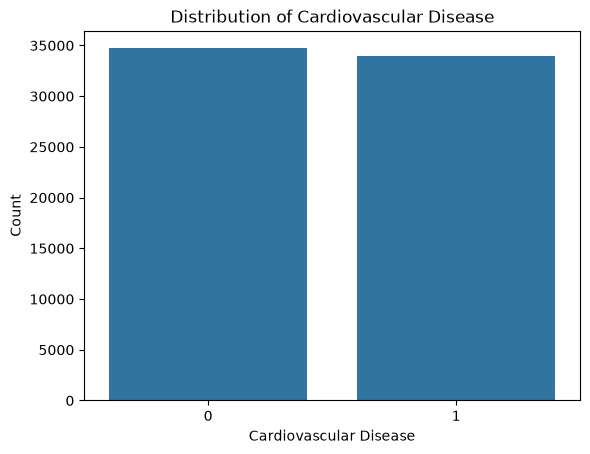

In [22]:
sns.countplot(data=cleaned_data, x='cardio')
plt.title('Distribution of Cardiovascular Disease')
plt.xlabel('Cardiovascular Disease')
plt.ylabel('Count')
plt.show()

*Our data is already balanced - good to proceed* 

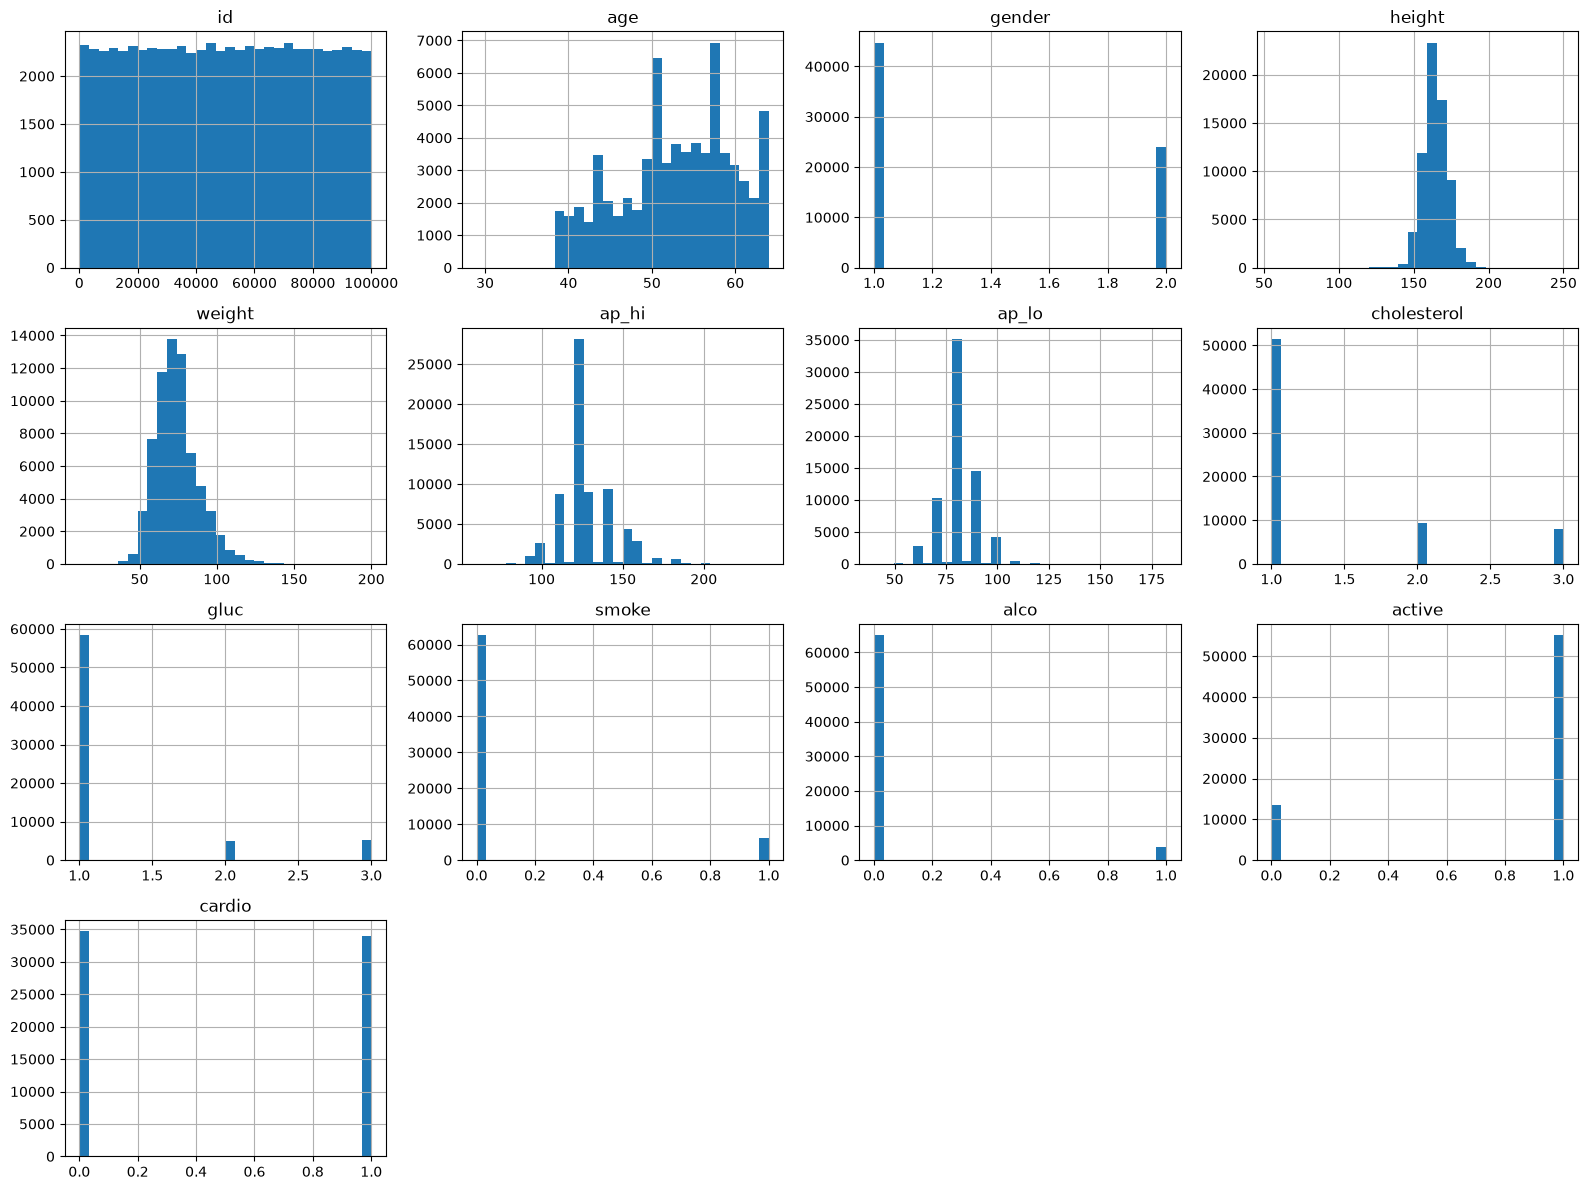

In [23]:
numerical_cols = cleaned_data.select_dtypes(
    include="number"
).columns

cleaned_data[numerical_cols].hist(
    figsize=(16, 12),
    bins=30
)

plt.tight_layout()
plt.show()


In [24]:
cleaned_data['age'] = np.log(cleaned_data['age']) + 1

**We check the distribution of the data**

In [25]:
cleaned_data.groupby('cardio').mean()

,id,age,gender,height,weight,ap_hi,ap_lo,cholesterol,gluc,smoke,alco,active
cardio,,,,,,,,,,,,
0,49868.196692,4.927243,1.345284,164.447823,71.568797,119.604023,78.125220,1.215914,1.175048,0.092539,0.055304,0.818064
1,50085.751332,4.990370,1.352044,164.272040,76.721920,133.895329,84.557531,1.516587,1.277485,0.083301,0.051364,0.788332


In [26]:
cleaned_data.corr()

,id,age,gender,height,weight,ap_hi,ap_lo,cholesterol,gluc,smoke,alco,active,cardio
id,1.000000,0.004425,0.003117,-0.002871,-0.002162,0.000917,-0.000349,0.005942,0.002278,-0.003852,0.000477,0.003541,0.003771
age,0.004425,1.000000,-0.025251,-0.080587,0.055560,0.209124,0.157752,0.153539,0.097874,-0.047515,-0.028635,-0.009923,0.237954
gender,0.003117,-0.025251,1.000000,0.499062,0.155970,0.062304,0.067518,-0.036835,-0.021229,0.338855,0.171271,0.005910,0.007093
height,-0.002871,-0.080587,0.499062,1.000000,0.291664,0.018716,0.036126,-0.050651,-0.018706,0.188288,0.094630,-0.007472,-0.010739
weight,-0.002162,0.055560,0.155970,0.291664,1.000000,0.271089,0.253599,0.141182,0.107086,0.067052,0.067445,-0.017757,0.179774
ap_hi,0.000917,0.209124,0.062304,0.018716,0.271089,1.000000,0.734944,0.195373,0.094331,0.027744,0.035528,-0.001039,0.427994
ap_lo,-0.000349,0.157752,0.067518,0.036126,0.253599,0.734944,1.000000,0.161477,0.074813,0.025166,0.037286,-0.000392,0.340144
cholesterol,0.005942,0.153539,-0.036835,-0.050651,0.141182,0.195373,0.161477,1.000000,0.450596,0.009775,0.035016,0.008601,0.221433
gluc,0.002278,0.097874,-0.021229,-0.018706,0.107086,0.094331,0.074813,0.450596,1.000000,-0.005901,0.010309,-0.007872,0.089602
smoke,-0.003852,-0.047515,0.338855,0.188288,0.067052,0.027744,0.025166,0.009775,-0.005901,1.000000,0.340543,0.025343,-0.016305


**We dont use any pipeline here since our data did not contain any cater feature and missing value, we proceed to model training**

# Model Training

In [27]:
from sklearn.model_selection import train_test_split

In [28]:
# Define X and y
X = cleaned_data.drop(columns=[
    'id',
    'cardio'
    
    
])

y = cleaned_data['cardio']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, stratify= y , test_size=0.2, random_state=42
)

In [29]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

# Fit and transform training data
X_train_scaled = scaler.fit_transform(X_train)

# Transform testing data
X_test_scaled = scaler.transform(X_test)

# Logistic Regression

In [30]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

In [31]:
model = LogisticRegression()

In [32]:
model.fit(X_train_scaled, y_train)

,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following

In [33]:
#Train data score
X_train_prediction = model.predict(X_train_scaled)
training_data_accuracy= accuracy_score(X_train_prediction, y_train)
print(training_data_accuracy)

0.7282523617962393


In [34]:
# Accuracy on the test data
X_test_prediction = model.predict(X_test_scaled)
test_data_accuracy = accuracy_score(X_test_prediction, y_test)
print('Accuracy on test data : ',test_data_accuracy)

Accuracy on test data :  0.7228977065890062


In [35]:
from sklearn.metrics import classification_report

X_train_prediction = model.predict(X_train_scaled)
X_test_prediction = model.predict(X_test_scaled)

print("Training Performance:")
print(classification_report(y_train, X_train_prediction))

print("Testing Performance:")
print(classification_report(y_test, X_test_prediction))

Training Performance:
              precision    recall  f1-score   support

           0       0.71      0.79      0.75     27759
           1       0.76      0.67      0.71     27178

    accuracy                           0.73     54937
   macro avg       0.73      0.73      0.73     54937
weighted avg       0.73      0.73      0.73     54937

Testing Performance:
              precision    recall  f1-score   support

           0       0.70      0.79      0.74      6940
           1       0.75      0.66      0.70      6795

    accuracy                           0.72     13735
   macro avg       0.73      0.72      0.72     13735
weighted avg       0.73      0.72      0.72     13735



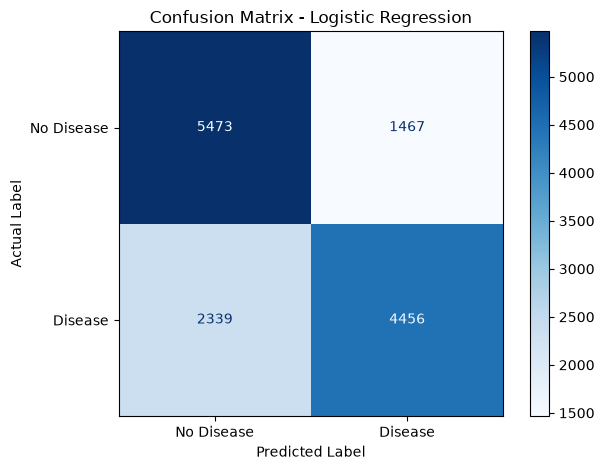

In [36]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# Create confusion matrix
cm = confusion_matrix(y_test, X_test_prediction)

# Plot confusion matrix
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=['No Disease', 'Disease']
)

disp.plot(cmap='Blues', values_format='d')

plt.title('Confusion Matrix - Logistic Regression')
plt.xlabel('Predicted Label')
plt.ylabel('Actual Label')
plt.tight_layout()

# Random Forest (Grid Search CV)

In [37]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GridSearchCV

In [38]:
model = RandomForestClassifier(random_state=42)

param_grid = {
    'n_estimators': [100, 200],
    'max_depth': [10, 20],
    'min_samples_split': [2, 5],
    'min_samples_leaf': [1, 2]
}

grid_search = GridSearchCV(
    estimator=RandomForestClassifier(random_state=42),
    param_grid=param_grid,
    cv=3,
    scoring='f1',
    n_jobs=-1,
    verbose=1
)

grid_search.fit(X_train, y_train)

Fitting 3 folds for each of 16 candidates, totalling 48 fits


,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",RandomForestC...ndom_state=42)
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'max_depth': [10, 20], 'min_samples_leaf': [1, 2], 'min_samples_split': [2, 5], 'n_estimators': [100, 200]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'f1'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",3
,"verbose verbose: int, default=0Controls the verbosity of information printed during fitting, with highervalues yielding more detailed logging.- 0 : no messages are printed;- >=1 : summary of the total number of fits;- >=2 : computation time for each fold and parameter candidate;- >=3 : fold indices and scores;- >=10 : parameter candidate indices and START messages before each fit.",1
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_select

In [39]:
print("Best parameters:", grid_search.best_params_)
print("Best CV F1-score:", grid_search.best_score_)

Best parameters: {'max_depth': 10, 'min_samples_leaf': 2, 'min_samples_split': 5, 'n_estimators': 200}
Best CV F1-score: 0.7165702039134182


# XGBosst

In [40]:
from xgboost import XGBClassifier

In [41]:
model = XGBClassifier(random_state = 42)

In [42]:
model.fit(X_train, y_train)

,"base_score base_score: typing.Union[float, typing.List[float], NoneType]The initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.Optional[typing.List[xgboost.callback.TrainingCallback]]List of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API <callback_api>`... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: typing.Optional[float]Subsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: typing.Optional[float]Subsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: typing.Optional[float]Subsample ratio of columns when constructing each tree.,None
,"device device: typing.Optional[str].. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: typing.Optional[int].. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",None
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,True
,"eval_metric eval_metric: typing.Union[str, typing.List[typing.Union[str, typing.Callable]], typing.Callable, NoneType].. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import load_diabetes from sklearn.metrics import mean_absolute_error X, y = load_diabetes(return_X_y=True) reg = xgb.XGBRegressor( tree_method=""hist"", eval_metric=mean_absolute_error, ) reg.fit(X, y, eval_set=[(X, y)])",None
,feature_types feature_types: typing.Optional[typing.Sequence[str]].. versionadded:: 1.7.0Used for specifying feature types without constructing a dataframe. Seethe :py:class:`DMatrix` for details.,None


In [43]:
#Train data score
X_train_prediction = model.predict(X_train)
training_data_accuracy= accuracy_score(X_train_prediction, y_train)
print(training_data_accuracy)

0.7597975863261555


In [44]:
# Accuracy on the test data
X_test_prediction = model.predict(X_test)
test_data_accuracy = accuracy_score(X_test_prediction, y_test)
print('Accuracy on test data : ',test_data_accuracy)

Accuracy on test data :  0.7299599563159811


In [45]:
X_train_prediction = model.predict(X_train)
X_test_prediction = model.predict(X_test)

print("Training Performance:")
print(classification_report(y_train, X_train_prediction))

print("Testing Performance:")
print(classification_report(y_test, X_test_prediction))

Training Performance:
              precision    recall  f1-score   support

           0       0.74      0.80      0.77     27759
           1       0.78      0.72      0.75     27178

    accuracy                           0.76     54937
   macro avg       0.76      0.76      0.76     54937
weighted avg       0.76      0.76      0.76     54937

Testing Performance:
              precision    recall  f1-score   support

           0       0.72      0.77      0.74      6940
           1       0.75      0.69      0.72      6795

    accuracy                           0.73     13735
   macro avg       0.73      0.73      0.73     13735
weighted avg       0.73      0.73      0.73     13735



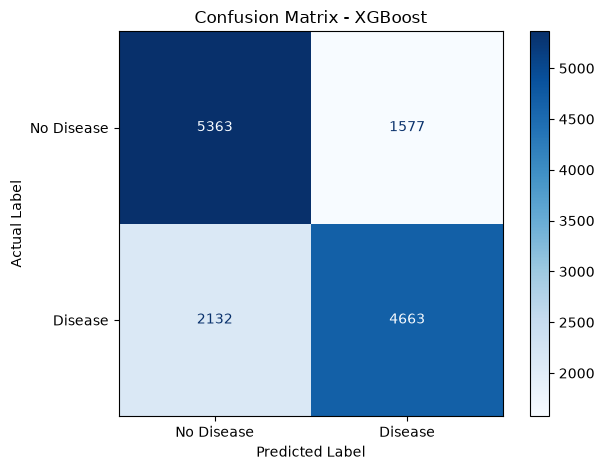

In [46]:
# Create confusion matrix
cm = confusion_matrix(y_test, X_test_prediction)

# Plot confusion matrix
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=['No Disease', 'Disease']
)

disp.plot(cmap='Blues', values_format='d')

plt.title('Confusion Matrix - XGBoost')
plt.xlabel('Predicted Label')
plt.ylabel('Actual Label')
plt.tight_layout()

# Conclusion

## Cardiovascular Disease Detection: Model Evaluation and Comparison

##  Best-Performing Model

**XGBoost is the best-performing model among the evaluated algorithms based on the available test results.** It achieves the highest test accuracy, recall, and F1-score compared with Logistic Regression. Random Forest was also evaluated using GridSearchCV, achieving a cross-validation F1-score of 0.7165.

##  Performance Comparison

| Metric | Logistic Regression | XGBoost | Random Forest (GridSearchCV) |
|---|---:|---:|---:|
| Test Accuracy | 0.72 | **0.73** | ~0.72 |
| Disease Precision (Class 1) | 0.75 | **0.75** | Not available |
| Disease Recall (Class 1) | 0.66 | **0.69** | Not available |
| Disease F1-Score (Class 1) | 0.70 | **0.72** | Not available |
| True Positives | 4,456 | **4,663** | Not available |
| False Negatives | 2,339 | **2,132** | Not available |
| Cross-Validation F1-Score | Not available | Not available | 0.7165 |

*Note: Random Forest's reported F1-score is from cross-validation, while the other reported metrics are test-set results. These values should not be compared directly without evaluating all models under the same conditions.*

##  Key Findings

### 1. Higher Disease Detection Rate

XGBoost achieves a recall of **0.69**, compared with 0.66 for Logistic Regression. This means XGBoost identifies a larger proportion of actual cardiovascular disease cases in the test set.

- **XGBoost:** 4,663 true positives and 2,132 false negatives.
- **Logistic Regression:** 4,456 true positives and 2,339 false negatives.

XGBoost identifies 207 additional disease cases and reduces false negatives by 207 compared with Logistic Regression.

### 2. Better Overall Performance

XGBoost achieves a test accuracy of 0.73 and an F1-score of 0.72, outperforming Logistic Regression, which achieves 0.72 accuracy and a 0.70 F1-score.

These results suggest that XGBoost provides a better balance between precision and recall on the evaluated test set.

### 3. Precision-Recall Trade-Off

Both models achieve a disease-class precision of 0.75, while XGBoost has higher recall (0.69 versus 0.66).

This indicates that XGBoost detects more actual disease cases while maintaining similar precision. However, its recall of 0.69 also means that approximately 31% of actual positive cases in the test set are still missed.

##  Overall Conclusion

Based on the available evaluation results, **XGBoost is the preferred model for further development** because it achieves the highest test accuracy, disease-class recall, and F1-score among the models with reported test metrics.

Since missing cardiovascular disease cases can have serious consequences, further improvements should focus on increasing recall while maintaining an acceptable precision level. Potential approaches include hyperparameter tuning, class weighting, and decision-threshold adjustment.




# Save Model

In [47]:
final_model = XGBClassifier(random_state = 42)
final_model.fit(X_train, y_train)

,"base_score base_score: typing.Union[float, typing.List[float], NoneType]The initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.Optional[typing.List[xgboost.callback.TrainingCallback]]List of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API <callback_api>`... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: typing.Optional[float]Subsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: typing.Optional[float]Subsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: typing.Optional[float]Subsample ratio of columns when constructing each tree.,None
,"device device: typing.Optional[str].. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: typing.Optional[int].. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",None
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,True
,"eval_metric eval_metric: typing.Union[str, typing.List[typing.Union[str, typing.Callable]], typing.Callable, NoneType].. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import load_diabetes from sklearn.metrics import mean_absolute_error X, y = load_diabetes(return_X_y=True) reg = xgb.XGBRegressor( tree_method=""hist"", eval_metric=mean_absolute_error, ) reg.fit(X, y, eval_set=[(X, y)])",None
,feature_types feature_types: typing.Optional[typing.Sequence[str]].. versionadded:: 1.7.0Used for specifying feature types without constructing a dataframe. Seethe :py:class:`DMatrix` for details.,None


In [48]:
import pickle

In [49]:
filename = 'cardiovascular_detection_model.pkl'
pickle.dump(final_model,open(filename, 'wb'))